# m06 - Extrapolation Stress Tests

Spatial CV holds out *places* but every fold still draws from the same overall range of conditions. A deployed surrogate
may be asked about conditions it has never seen (higher terrain, wetter climate, another end of the province). Here each
split trains on one regime and tests on a different one:

| split | train | test |
| --- | --- | --- |
| `elev low->high` / `high->low` | < 100 m / >= 300 m | >= 300 m / < 100 m |
| `south->north` / `north->south` | rows < 45 / >= 90 | rows >= 90 / < 45 |
| `west->east` / `east->west` | cols < 62 / >= 124 | cols >= 124 / < 62 |
| `rain low->high` / `high->low` | bio12 below its 40th / above its 60th percentile | above its 80th / below its 20th |

A 'gap' region between train and test keeps neighbours from leaking across the boundary. Metrics are computed on the
test regime only; `ood_share` is the fraction of test cells with at least one feature outside the training min-max range.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
targets = {c: df[E.target_col(c)].to_numpy() for c in E.CROPS}   # GAEZ v5 at 1 km (E.TARGET_RES)
elev, row, col, rain = (df[k].to_numpy() for k in ["elevation_mean_m", "row", "col", "bio12_precip_annual_mm"])
elev = np.where(np.isnan(elev), np.nanmedian(elev), elev)
q = lambda a, p: np.quantile(a, p)

def pair(name_a, a, name_b, b):
    return {name_a: [(np.where(a)[0], np.where(b)[0])], name_b: [(np.where(b)[0], np.where(a)[0])]}

splits = {}
splits |= pair("elev low->high", elev < 100, "elev high->low", elev >= 300)
splits |= pair("south->north", row < 45, "north->south", row >= 90)
splits |= pair("west->east", col < 62, "east->west", col >= 124)
splits |= {"rain low->high": [(np.where(rain < q(rain, .4))[0], np.where(rain > q(rain, .8))[0])],
           "rain high->low": [(np.where(rain > q(rain, .6))[0], np.where(rain < q(rain, .2))[0])]}

X = df[E.feature_columns()].to_numpy(float)
diag = []
for name, [(tr, te)] in splits.items():
    lo, hi = np.nanmin(X[tr], axis=0), np.nanmax(X[tr], axis=0)
    ood = ((X[te] < lo) | (X[te] > hi)).any(axis=1)
    diag.append({"split": name, "train_cells": len(tr), "test_cells": len(te), "ood_share": ood.mean()})
diag = pd.DataFrame(diag).set_index("split")
diag.round(3)

,train_cells,test_cells,ood_share
split,,,
elev low->high,5658,1460,1.000
elev high->low,1460,5658,1.000
south->north,2946,2299,1.000
north->south,2299,2946,1.000
west->east,767,3626,0.972
east->west,3626,767,0.120
rain low->high,3651,1820,1.000
rain high->low,3640,1816,1.000


In [3]:
MODELS = ["dummy", "ridge", "knn", "et", "hgb", "xgb"]
res, _ = E.run_grid(df, targets, MODELS, [], custom_splits=splits)
E.save_table(res, "m06_extrapolation_raw")
r2 = res.groupby(["model", "scheme"])["r2"].mean().unstack("scheme")[list(splits)]
r2["mean"] = r2.mean(axis=1)
r2 = r2.sort_values("mean", ascending=False)
E.save_table(r2.round(4), "m06_extrapolation_r2", index=True)
r2.round(2)

480 tasks (6 models x 10 targets x 8 schemes x 1 repeats), 14 features


done in 13 s


scheme,elev low->high,elev high->low,south->north,north->south,west->east,east->west,rain low->high,rain high->low,mean
model,,,,,,,,,
et,-0.83,-0.60,-0.25,0.60,0.38,0.48,-0.23,-0.33,-0.10
hgb,-1.16,-0.36,-0.22,0.54,0.15,0.46,-0.60,-0.99,-0.27
knn,-1.73,-1.13,-0.59,0.35,0.22,-0.10,0.14,-1.20,-0.50
xgb,-1.90,-0.42,-1.34,0.54,-0.12,0.45,-0.75,-1.90,-0.68
ridge,-1.73,-0.71,-0.09,-2.21,-1.37,-0.24,-5.71,-0.02,-1.51
dummy,-36.61,-2.92,-1.06,-2.49,-0.11,-0.57,-27.19,-2.41,-9.17


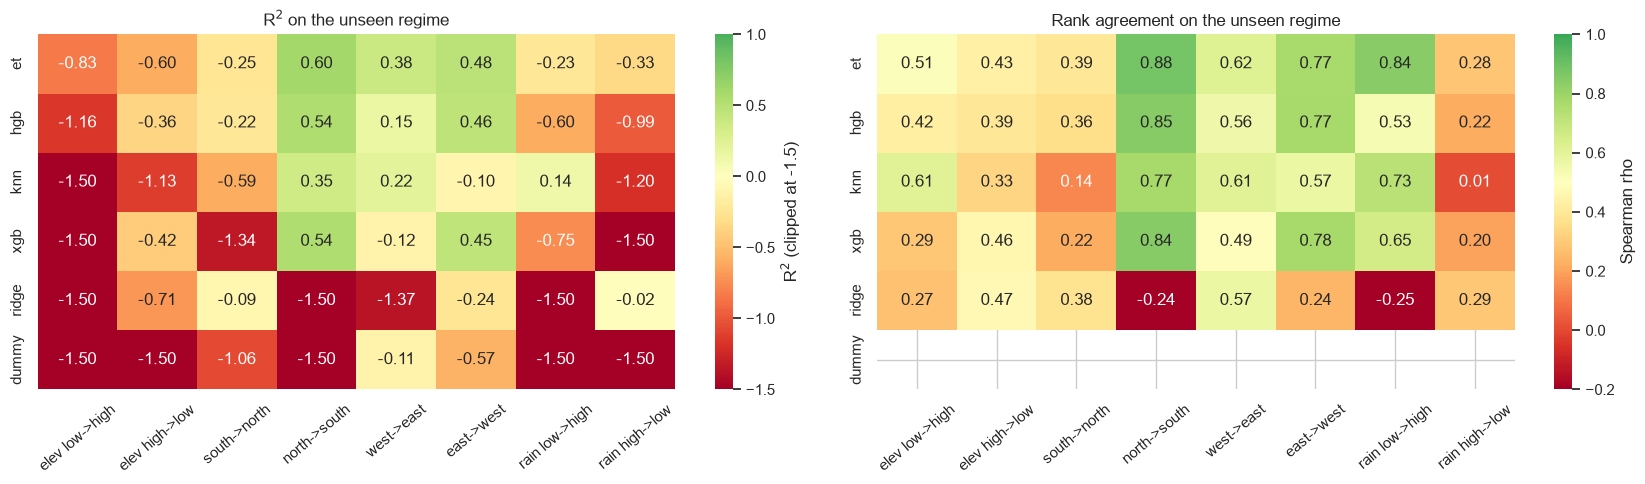

In [4]:
sp = res.groupby(["model", "scheme"])["spearman"].mean().unstack("scheme")[list(splits)]
sp["mean"] = sp.mean(axis=1)
E.save_table(sp.sort_values("mean", ascending=False).round(4), "m06_extrapolation_spearman", index=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.heatmap(r2.drop(columns="mean").clip(lower=-1.5), annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-1.5, vmax=1, ax=axes[0],
            cbar_kws={"label": "R$^2$ (clipped at -1.5)"})
axes[0].set(title="R$^2$ on the unseen regime", xlabel="", ylabel="")
sns.heatmap(sp.drop(columns="mean").loc[r2.index], annot=True, fmt=".2f", cmap="RdYlGn", center=0.5, vmin=-0.2, vmax=1, ax=axes[1],
            cbar_kws={"label": "Spearman rho"})
axes[1].set(title="Rank agreement on the unseen regime", xlabel="", ylabel="")
for ax in axes: ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
E.save_fig(fig, "m06_extrapolation")
plt.show()

## What fails first?
Per-crop R$^2$ of the best tree model and the best smooth model on the two elevation splits.

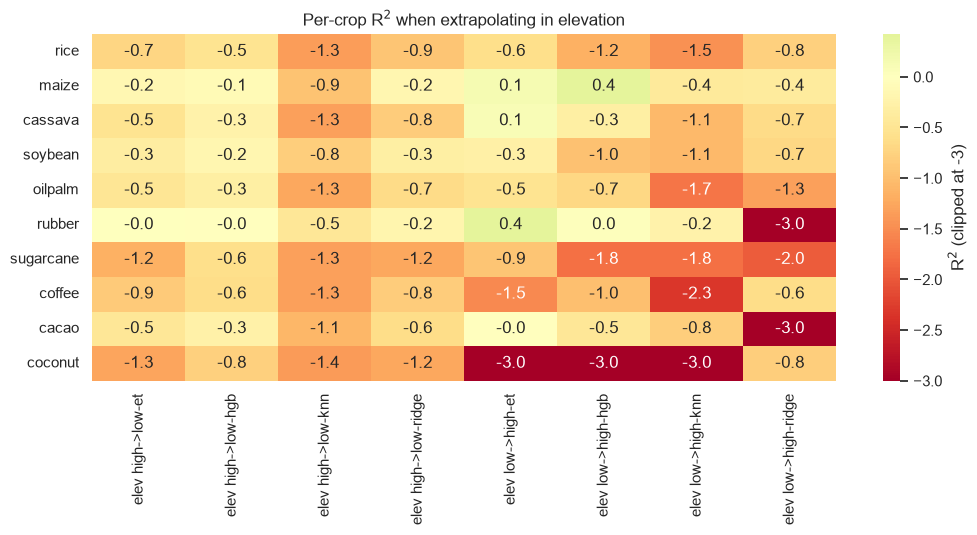

In [5]:
sub = res[res.scheme.isin(["elev low->high", "elev high->low"]) & res.model.isin(["hgb", "et", "knn", "ridge"])]
piv = sub.groupby(["target", "scheme", "model"])["r2"].mean().unstack(["scheme", "model"]).loc[E.CROPS]
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(piv.clip(lower=-3), annot=True, fmt=".1f", cmap="RdYlGn", center=0, ax=ax, cbar_kws={"label": "R$^2$ (clipped at -3)"})
ax.set(title="Per-crop R$^2$ when extrapolating in elevation", xlabel="", ylabel="")
E.save_fig(fig, "m06_elevation_by_crop")
plt.show()